---
---

# Clustering Flight Delay Patterns for Operational Optimization
---
---

## Summary of the Pitch

Airlines suffer costly and frequent delays caused by factors such as weather, carrier issues, NAS, and late aircraft.

The goal is to cluster flights based on delay behavior to uncover actionable operational patterns.

A 5% reduction in delay-related costs can save airlines millions annually.

The dataset contains real-world U.S. Bureau of Transportation Statistics delay records (2015–2019).

Clustering these delay patterns enables targeted planning, resource allocation, and improved punctuality.

# Imports and Settings

In [37]:
import pandas as pd
# make pandas display ALL columns of a dataframe
pd.options.display.max_columns = None
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import OPTICS
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# 1. The Data

## Data Source

- Source: U.S. Department of Transportation, Bureau of Transportation Statistics (BTS).
- Access: "Airline On-Time Statistics and Delay Causes" dashboard on the BTS TranStats portal.
- Author: BTS, based on mandatory on-time performance reports from U.S. air carriers.
- License: Public U.S. Government data, openly available for analysis and reuse.
- Purpose: Monitor on-time performance, delays, cancellations, and their causes for domestic U.S. flights.


## The Raw Data

In [38]:

raw_data = pd.read_csv("Airline_Delay_Cause.csv")

display(raw_data.head())
print(raw_data.shape)


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2019,12,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",53.0,6.0,3.05,0.22,0.21,0.00,2.52,0.0,0.0,265.0,110.0,10.0,6.0,0.0,139.0
1,2019,12,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",115.0,4.0,0.03,0.00,1.35,0.00,2.62,0.0,2.0,157.0,1.0,0.0,40.0,0.0,116.0
2,2019,12,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",191.0,13.0,7.49,2.31,1.48,0.00,1.73,0.0,1.0,678.0,332.0,153.0,82.0,0.0,111.0
3,2019,12,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",6.0,1.0,0.00,0.00,1.00,0.00,0.00,0.0,0.0,19.0,0.0,0.0,19.0,0.0,0.0
4,2019,12,9E,Endeavor Air Inc.,ATL,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern...",3804.0,470.0,116.84,11.79,148.86,0.45,192.07,3.0,0.0,32926.0,11584.0,608.0,4885.0,93.0,15756.0


(89077, 21)


## Feature Description

| Feature               | Range / Type                               | Explanation                                                                                 |
|-----------------------|--------------------------------------------|---------------------------------------------------------------------------------------------|
| year                  | Integer, 2015–2019                         | Calendar year of the observation.                                                           |
| month                 | Integer, 1–12                              | Month of the year (1 = January, …, 12 = December).                                         |
| carrier               | String airline code (e.g., "AA", "DL")     | Two-letter/combination code of the marketing carrier.                                      |
| carrier_name          | Text                                      | Full name of the airline.                                                                  |
| airport               | 3-letter IATA airport code (e.g., "ATL")   | Code of the arrival airport.                                                               |
| airport_name          | Text                                      | Full descriptive name of the airport and city.                                             |
| arr_flights           | Non-negative float (count)                 | Number of arriving flights in the given month for this carrier–airport combination.        |
| arr_del15             | Non-negative float (count)                 | Number of arrivals delayed by 15 minutes or more.                                          |
| carrier_ct            | Non-negative float (count)                 | Number of delayed flights attributed to carrier-related causes.                            |
| weather_ct            | Non-negative float (count)                 | Number of delayed flights attributed to weather.                                           |
| nas_ct                | Non-negative float (count)                 | Number of delayed flights attributed to NAS (National Aviation System) causes.             |
| security_ct           | Non-negative float (count)                 | Number of delayed flights attributed to security issues.                                   |
| late_aircraft_ct      | Non-negative float (count)                 | Number of delayed flights caused by the previous flight of the same aircraft arriving late.|
| arr_cancelled         | Non-negative float (count)                 | Number of cancelled arrival flights.                                                       |
| arr_diverted          | Non-negative float (count)                 | Number of flights diverted to another airport.                                             |
| arr_delay             | Non-negative float (minutes)               | Total arrival delay minutes for all delayed flights (≥ 15 minutes).                        |
| carrier_delay         | Non-negative float (minutes)               | Total delay minutes caused by carrier-related issues.                                      |
| weather_delay         | Non-negative float (minutes)               | Total delay minutes caused by weather.                                                     |
| nas_delay             | Non-negative float (minutes)               | Total delay minutes attributed to NAS causes.                                              |
| security_delay        | Non-negative float (minutes)               | Total delay minutes caused by security events.                                             |
| late_aircraft_delay   | Non-negative float (minutes)               | Total delay minutes caused by late-arriving aircraft.                                      |


## Suitability for the Task

- The dataset contains multi-year, real-world flight performance data, making it large, meaningful, and suitable for statistical exploration.
- It includes detailed delay causes (carrier, weather, NAS, security, late aircraft), which directly supports clustering flights by delay patterns.
- All features are numeric or easily convertible, matching the requirements for PCA, dimensionality reduction, and clustering methods in this project.


# 2. Initial Data Analysis

## Initial Data Analysis

In [39]:
# Basic shape: how many rows and columns does the dataset have?
rows, columns = raw_data.shape
print(f"Rows: {rows}    Columns: {columns}")


# Basic numeric statistics for all numerical features
print("Basic statistics of numerical features:")
display(raw_data.describe().T)

# Number of missing values per column
print("\nMissing values per column:")
print(raw_data.isna().sum())



Rows: 89077    Columns: 21
Basic statistics of numerical features:


,count,mean,std,min,25%,50%,75%,max
year,89077.0,2017.419850,1.417635,2015.0,2016.00,2018.00,2019.0000,2019.00
month,89077.0,6.519461,3.453347,1.0,4.00,7.00,10.0000,12.00
arr_flights,88978.0,371.459675,1020.752204,1.0,52.00,102.00,253.0000,21977.00
arr_del15,88955.0,68.194199,177.058846,0.0,7.00,19.00,48.0000,4176.00
carrier_ct,88978.0,19.331375,45.121156,0.0,2.33,6.32,16.1300,1242.16
weather_ct,88978.0,2.183827,6.718907,0.0,0.00,0.41,1.8200,240.79
nas_ct,88978.0,21.484163,65.885117,0.0,1.39,4.42,12.5000,1884.42
security_ct,88978.0,0.122153,0.539240,0.0,0.00,0.00,0.0000,19.53
late_aircraft_ct,88978.0,25.055072,69.550894,0.0,2.00,6.13,16.6075,1443.45
arr_cancelled,88978.0,5.917867,24.564499,0.0,0.00,1.00,4.0000,1283.00



Missing values per column:
year                     0
month                    0
carrier                  0
carrier_name             0
airport                  0
airport_name             0
arr_flights             99
arr_del15              122
carrier_ct              99
weather_ct              99
nas_ct                  99
security_ct             99
late_aircraft_ct        99
arr_cancelled           99
arr_diverted            99
arr_delay               99
carrier_delay           99
weather_delay           99
nas_delay               99
security_delay          99
late_aircraft_delay     99
dtype: int64


In [40]:
# Structed overview
print("\nInfo about data:")          
print(raw_data.info())


Info about data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89077 entries, 0 to 89076
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 89077 non-null  int64  
 1   month                89077 non-null  int64  
 2   carrier              89077 non-null  object 
 3   carrier_name         89077 non-null  object 
 4   airport              89077 non-null  object 
 5   airport_name         89077 non-null  object 
 6   arr_flights          88978 non-null  float64
 7   arr_del15            88955 non-null  float64
 8   carrier_ct           88978 non-null  float64
 9   weather_ct           88978 non-null  float64
 10  nas_ct               88978 non-null  float64
 11  security_ct          88978 non-null  float64
 12  late_aircraft_ct     88978 non-null  float64
 13  arr_cancelled        88978 non-null  float64
 14  arr_diverted         88978 non-null  float64
 15  arr_delay         

- The dataset contains a large number of observations (rows) with more than 20 features, covering several years of U.S. flight operations.
- The time span includes multiple calendar years (2015–2019) and many different carriers and airports, which makes the data suitable for comparing delay behavior across airlines and locations.
- Several delay-related columns (both *_ct and *_delay features) contain missing values, which need to be handled during preprocessing.
- The descriptive statistics show that delay counts and delay minutes are highly skewed: most months have moderate delays, but a few months exhibit very large aggregated delay values.
- Overall, the dataset is rich, high-dimensional, and contains enough variability to justify dimensionality reduction and clustering in the later tasks.


# 3. Preprocessing

In [41]:
# Replacing NaN with 0 is meaningful, because it means "no delay recorded".
raw_data = raw_data.fillna(0)

# Strip whitespace from column names
raw_data.columns = raw_data.columns.str.strip()

print(raw_data.isna().sum())

year                   0
month                  0
carrier                0
carrier_name           0
airport                0
airport_name           0
arr_flights            0
arr_del15              0
carrier_ct             0
weather_ct             0
nas_ct                 0
security_ct            0
late_aircraft_ct       0
arr_cancelled          0
arr_diverted           0
arr_delay              0
carrier_delay          0
weather_delay          0
nas_delay              0
security_delay         0
late_aircraft_delay    0
dtype: int64


In [42]:
# Create new columns

# Create delay_rate: proportion of flights delayed by >=15 minutes
raw_data['delay_rate'] = (raw_data['arr_del15'] / raw_data['arr_flights']) * 100 #delay_rate — shows the percentage of delays of 15+ minutes
# Create total_delay_hours: total delay minutes converted to hours
raw_data['total_delay_hours'] = raw_data['arr_delay'] / 60   #total_delay_hours — converts total delay from minutes to hours
raw_data.head()

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,delay_rate,total_delay_hours
0,2019,12,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",53.0,6.0,3.05,0.22,0.21,0.00,2.52,0.0,0.0,265.0,110.0,10.0,6.0,0.0,139.0,11.320755,4.416667
1,2019,12,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",115.0,4.0,0.03,0.00,1.35,0.00,2.62,0.0,2.0,157.0,1.0,0.0,40.0,0.0,116.0,3.478261,2.616667
2,2019,12,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",191.0,13.0,7.49,2.31,1.48,0.00,1.73,0.0,1.0,678.0,332.0,153.0,82.0,0.0,111.0,6.806283,11.300000
3,2019,12,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",6.0,1.0,0.00,0.00,1.00,0.00,0.00,0.0,0.0,19.0,0.0,0.0,19.0,0.0,0.0,16.666667,0.316667
4,2019,12,9E,Endeavor Air Inc.,ATL,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern...",3804.0,470.0,116.84,11.79,148.86,0.45,192.07,3.0,0.0,32926.0,11584.0,608.0,4885.0,93.0,15756.0,12.355415,548.766667


In [43]:
#Removing meaningless rows (no flights)
raw_data = raw_data[raw_data['arr_flights'] > 0]
rows, columns = raw_data.shape
print(f"Rows: {rows}    Columns: {columns}")
data_full = raw_data.copy()
data_full.head()

Rows: 88978    Columns: 23


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,delay_rate,total_delay_hours
0,2019,12,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",53.0,6.0,3.05,0.22,0.21,0.00,2.52,0.0,0.0,265.0,110.0,10.0,6.0,0.0,139.0,11.320755,4.416667
1,2019,12,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",115.0,4.0,0.03,0.00,1.35,0.00,2.62,0.0,2.0,157.0,1.0,0.0,40.0,0.0,116.0,3.478261,2.616667
2,2019,12,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",191.0,13.0,7.49,2.31,1.48,0.00,1.73,0.0,1.0,678.0,332.0,153.0,82.0,0.0,111.0,6.806283,11.300000
3,2019,12,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",6.0,1.0,0.00,0.00,1.00,0.00,0.00,0.0,0.0,19.0,0.0,0.0,19.0,0.0,0.0,16.666667,0.316667
4,2019,12,9E,Endeavor Air Inc.,ATL,"Atlanta, GA: Hartsfield-Jackson Atlanta Intern...",3804.0,470.0,116.84,11.79,148.86,0.45,192.07,3.0,0.0,32926.0,11584.0,608.0,4885.0,93.0,15756.0,12.355415,548.766667


- Missing values in delay-related features were replaced with 0, since NaN represents “no delay recorded” and therefore logically corresponds to zero delay.
- Rows with zero arriving flights were removed because delay rates and delay hours per flight cannot be computed meaningfully for these cases.
- Two additional features were engineered:
  - **delay_rate**: share of flights delayed by 15+ minutes (in %),
  - **total_delay_hours**: total arrival delay converted from minutes to hours.
- Rows with zero flights are removed after computing `delay_rate`, so the remaining rows contain no division-by-zero values.
- The final preprocessed dataset is stored as **data_full** and will be used for all subsequent analyses.


# 4. Exploratory Data Analysis

## Correlation of Delay Causes

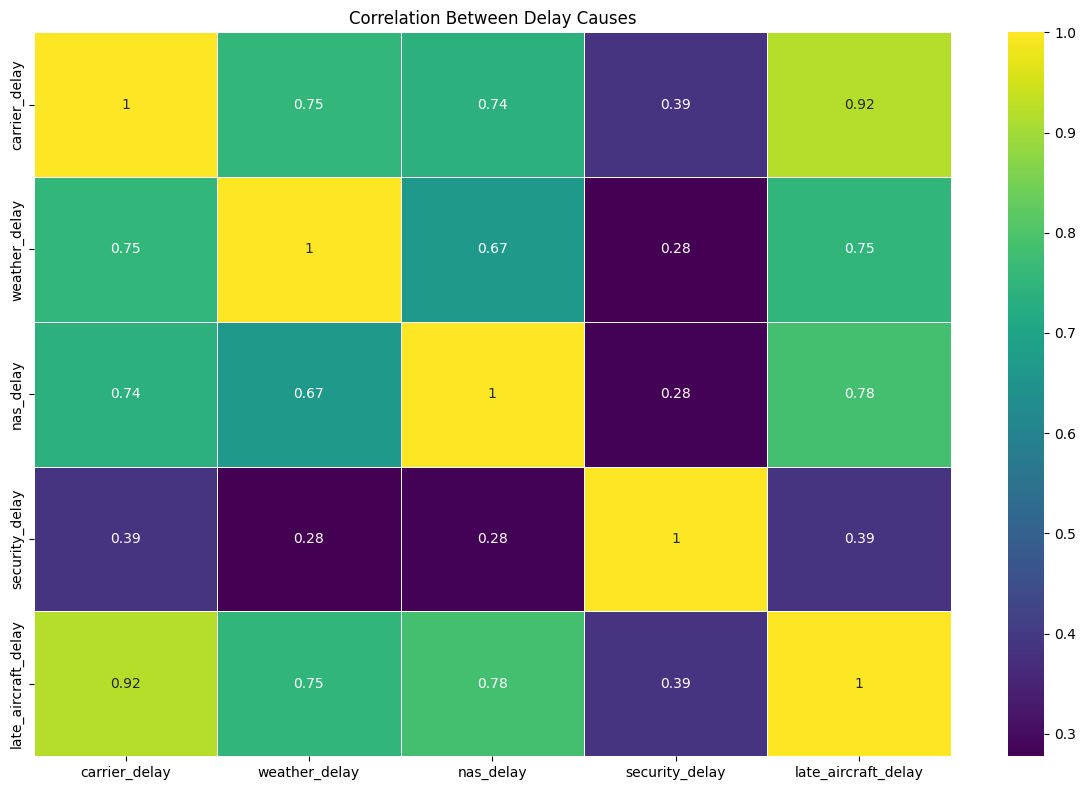

In [44]:
delay_columns = ['carrier_delay','weather_delay','nas_delay','security_delay','late_aircraft_delay']
corr = data_full[delay_columns].corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=True, cmap='viridis', linewidths=.5)
plt.title('Correlation Between Delay Causes')
plt.tight_layout(); plt.show()

**Task 4 – Correlation Between Delay Causes** 

Strong positive correlations appear between `late_aircraft_delay` and `carrier_delay`, indicating that these causes tend to occur together and contribute most to total delay minutes.
Weather and security delays show weaker correlations with the other delay types, suggesting they act more independently.
The heatmap highlights the dominant role of carrier-related and late-aircraft issues in shaping overall delay patterns.



## Delay Rate vs Total Delay Hours

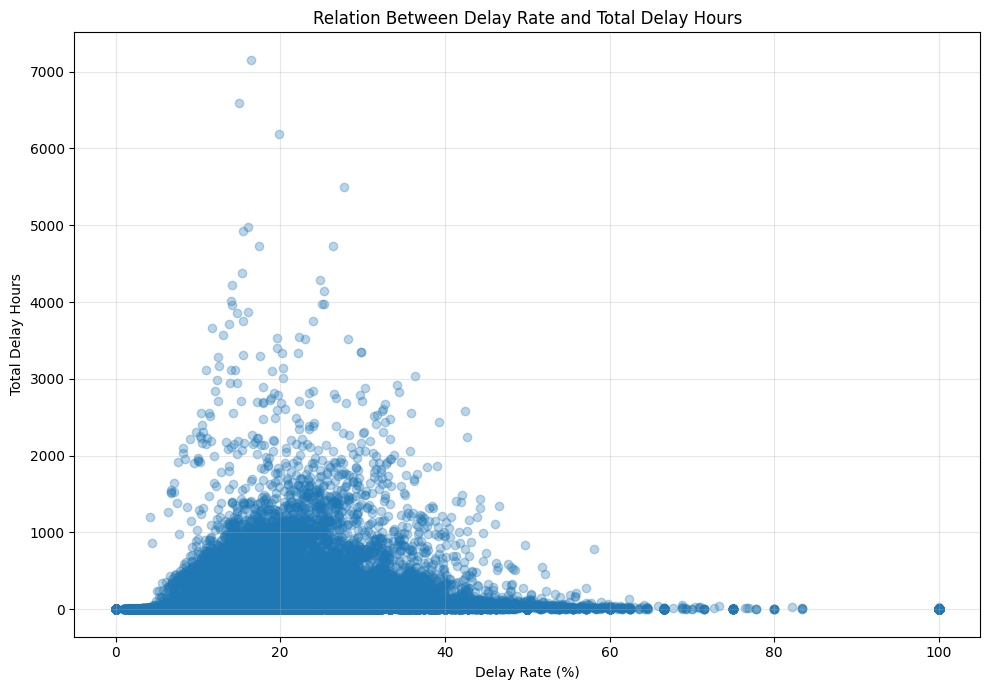

In [45]:
plt.figure(figsize=(10,7))
plt.scatter(data_full['delay_rate'], data_full['total_delay_hours'], alpha=0.3)
plt.xlabel('Delay Rate (%)')
plt.ylabel('Total Delay Hours')
plt.title('Relation Between Delay Rate and Total Delay Hours')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Relation between vs Total Delay hours**

The plot shows that most airline–airport–month entries have a delay rate between 0% and 30%, but even in this range the total delay hours can become very large.
 Many points with a delay rate of around 10–25% still reach thousands of total delay hours. This means that even a moderate percentage of delayed flights can create a huge amount of total delay when the number of flights is high.
 Some cases show very high delay rates (60–100%), but their total delay hours are low. This usually happens when there are only a few flights in that month.
 Overall, the plot shows that a high amount of total delay does not require a high delay rate. Even a relatively small share of delayed flights can cause large total delays when traffic volume is high.


## Carrier-Level Delay Patterns and Worst-Performing Airlines

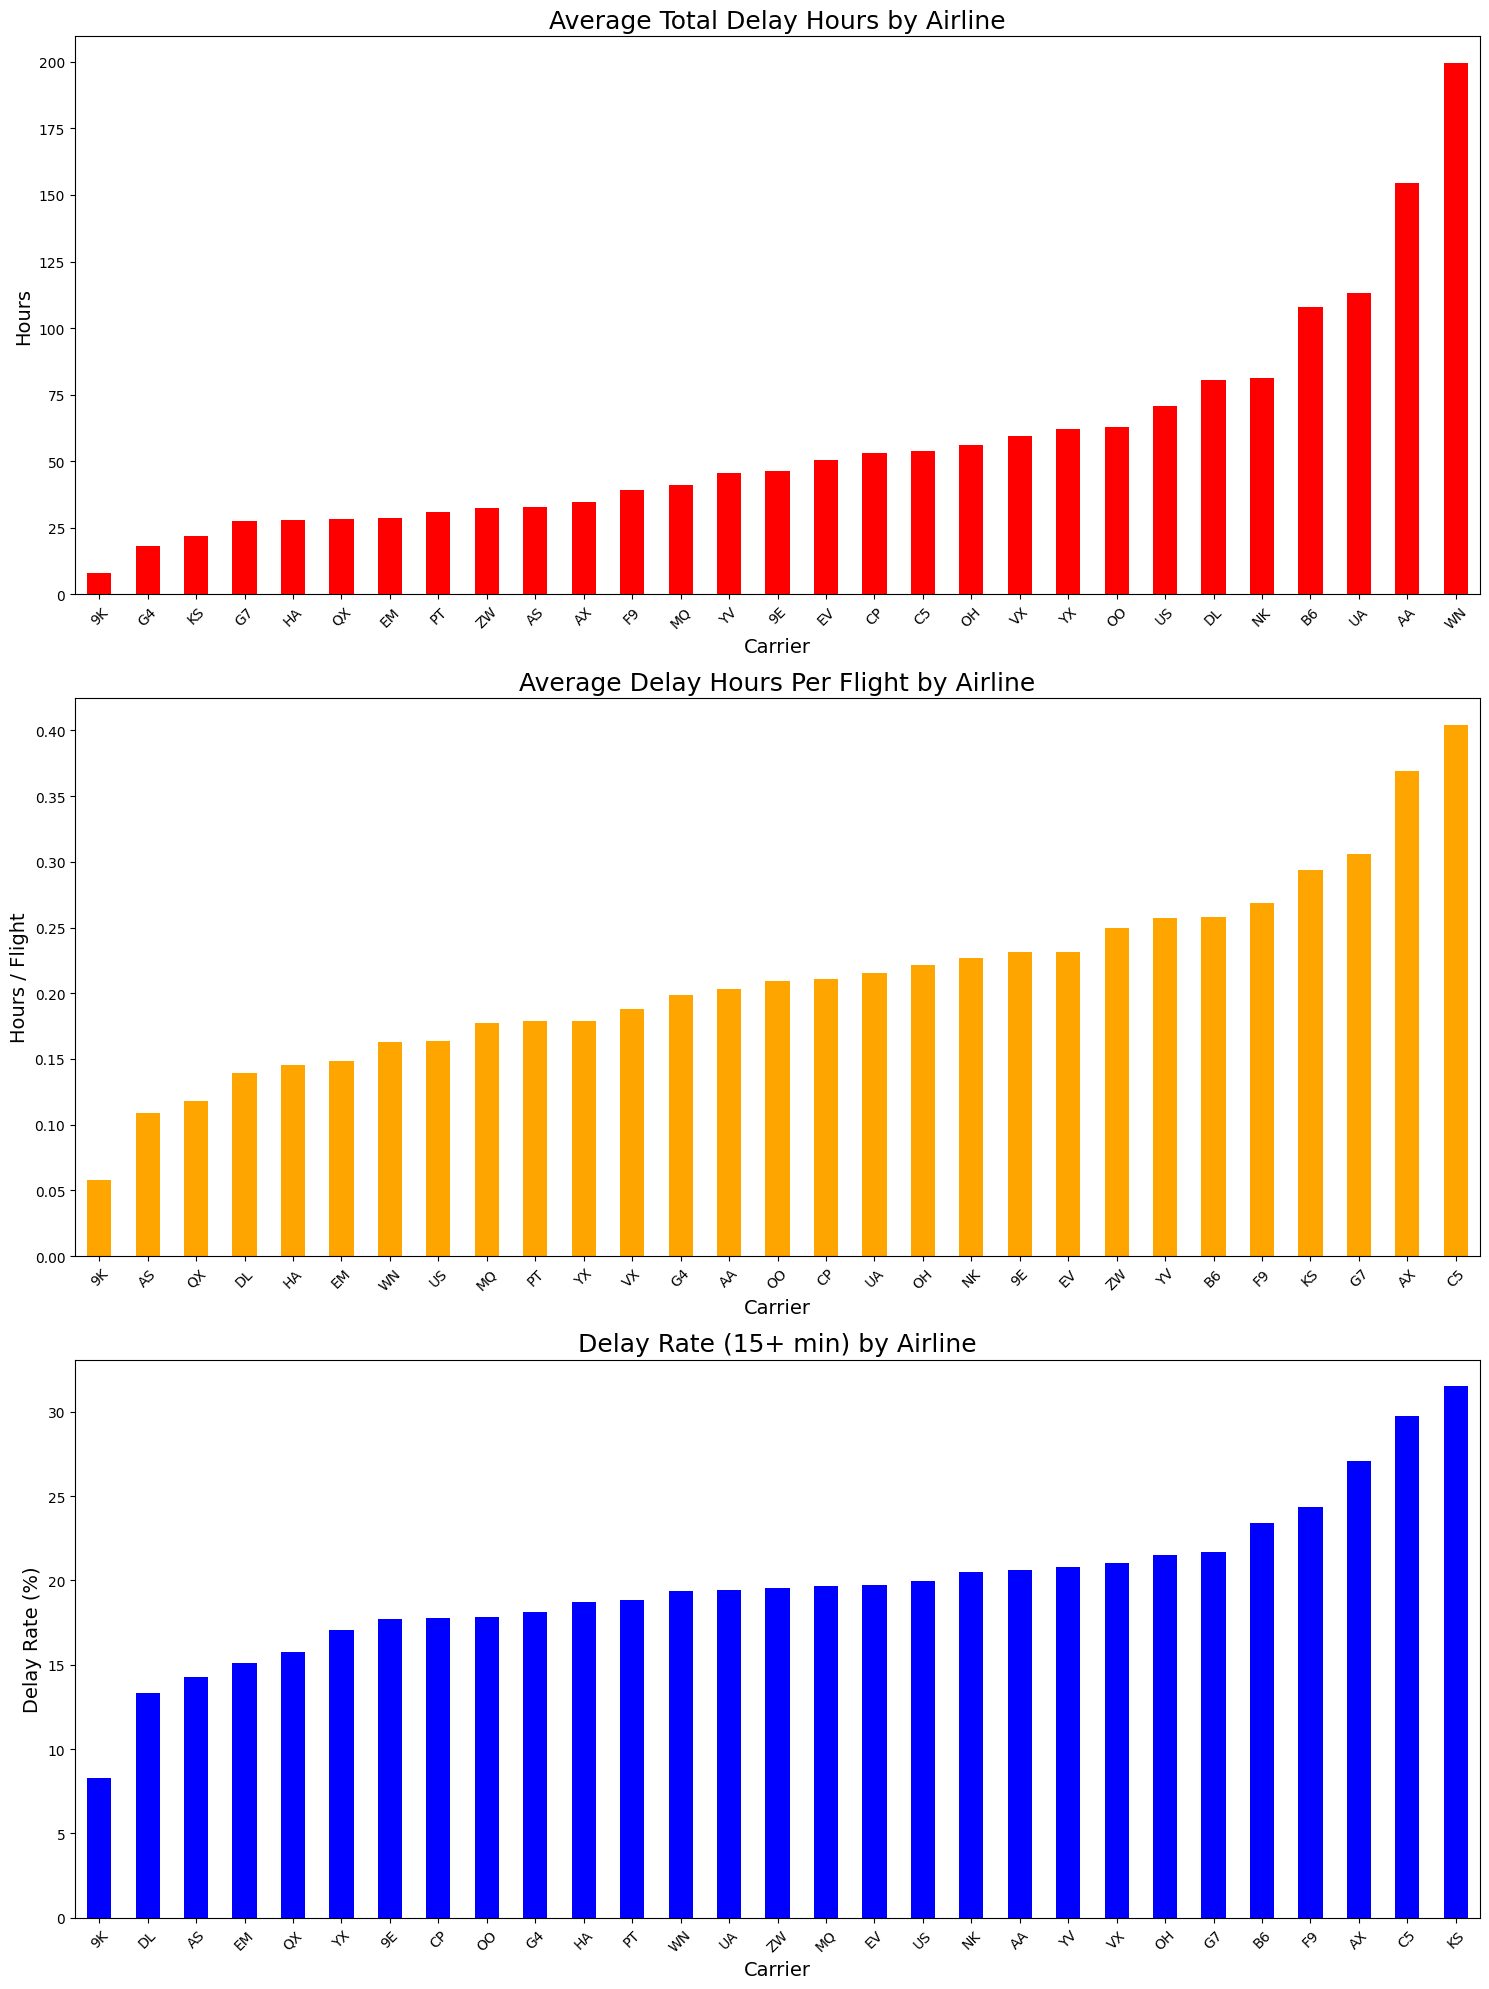

In [46]:
carrier_total_delay = data_full.groupby("carrier")["total_delay_hours"].mean().sort_values()    #total carirer delays

data_full["delay_hours_per_flight"] = data_full["total_delay_hours"] / data_full["arr_flights"]        
carrier_per_flight = data_full.groupby("carrier")["delay_hours_per_flight"].mean().sort_values()  #delay hours per flight


carrier_delay_rate = data_full.groupby("carrier")["delay_rate"].mean().sort_values()   #delay rate 15min +

fig, axes = plt.subplots(3, 1, figsize=(15, 20))  

# average total deylay hours
carrier_total_delay.plot(kind="bar", ax=axes[0], color="red")
axes[0].set_title("Average Total Delay Hours by Airline", fontsize=18)
axes[0].set_xlabel("Carrier", fontsize=14)
axes[0].set_ylabel("Hours", fontsize=14)
axes[0].tick_params(axis='x', rotation=45, labelsize=10)

# average delay hours per flight 
carrier_per_flight.plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Average Delay Hours Per Flight by Airline", fontsize=18)
axes[1].set_xlabel("Carrier", fontsize=14)
axes[1].set_ylabel("Hours / Flight", fontsize=14)
axes[1].tick_params(axis='x', rotation=45, labelsize=10)

#delay rate +15 min
carrier_delay_rate.plot(kind="bar", ax=axes[2], color="blue")
axes[2].set_title("Delay Rate (15+ min) by Airline", fontsize=18)
axes[2].set_xlabel("Carrier", fontsize=14)
axes[2].set_ylabel("Delay Rate (%)", fontsize=14)
axes[2].tick_params(axis='x', rotation=45, labelsize=10)

plt.tight_layout()
plt.show()

In [47]:
scores = pd.DataFrame({"total_delay_rank": carrier_total_delay.rank(ascending=False),"per_flight_rank": carrier_per_flight.rank(ascending=False),"delay_rate_rank": carrier_delay_rate.rank(ascending=False)})

scores["combined_score"] = (scores["total_delay_rank"]+ scores["per_flight_rank"]+ scores["delay_rate_rank"])

top5_worst = scores.sort_values("combined_score").head(5)
print(top5_worst)

         total_delay_rank  per_flight_rank  delay_rate_rank  combined_score
carrier                                                                    
C5                   12.0              1.0              2.0            15.0
B6                    4.0              6.0              5.0            15.0
AX                   19.0              2.0              3.0            24.0
F9                   18.0              5.0              4.0            27.0
NK                    5.0             11.0             11.0            27.0


**Delay Differences Between Airlines**

- The three bar charts show that airlines are not the same when it comes to delays. Some carriers collect much more total delay time than others.
- The first chart (total delay hours) shows which airlines have the highest amount of total delay. A few airlines stand out with very high numbers.
- The second chart (delay hours per flight) shows that even if an airline does not fly many flights, each of their flights can still be heavily delayed. This means the problem is not only flight volume but also how efficiently the airline operates.
- The third chart (delay rate) shows the percentage of flights delayed by 15+ minutes. Some airlines delay a much larger share of their flights compared to others.

- To combine these three delay measures into one simple score, each airline was ranked on:
  - total delay hours,
  - delay hours per flight,
  - delay rate.

- These ranks were added together to create a **combined delay score**. A lower score means the airline performs worse overall across all three metrics.

- From this combined score, we identified the **top 5 worst-performing airlines**. These airlines show the most delays in total, delay more flights, and have longer delays per flight.

- Overall, this analysis makes it clear that delays are not random. A small group of airlines consistently experiences more problems. These differences will be very useful later when we perform clustering, because the data already shows strong patterns between airlines.


# 5. Dimensionality Reduction with PCA

Explained variance ratio: [5.91940870e-01 8.40026872e-02 6.76772276e-02 5.06555841e-02
 4.84375320e-02 3.04724511e-02 2.88522440e-02 2.51427190e-02
 2.09175307e-02 1.83361364e-02 1.13712290e-02 8.16902434e-03
 6.02128245e-03 3.45923669e-03 2.40047827e-03 1.50603152e-03
 6.37735337e-04 1.78046620e-10 3.89304513e-11 6.51996934e-18]
Cumulative explained variance: [0.59194087 0.67594356 0.74362078 0.79427637 0.8427139  0.87318635
 0.9020386  0.92718132 0.94809885 0.96643498 0.97780621 0.98597524
 0.99199652 0.99545575 0.99785623 0.99936226 1.         1.
 1.         1.        ]


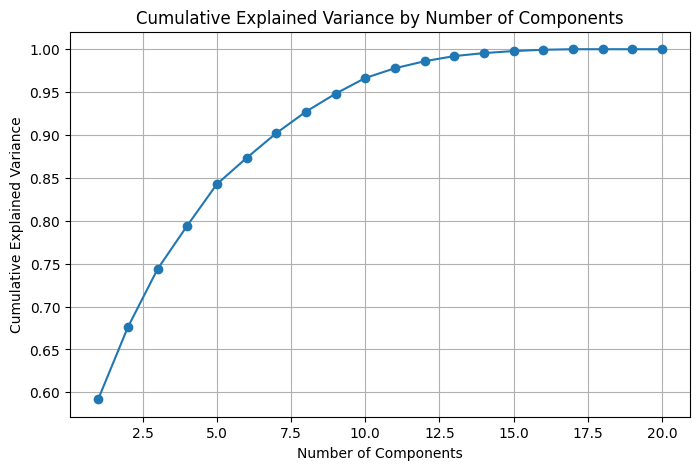

,PC1,PC2,PC3
0,-1.237808,-0.804394,-0.099607
1,-1.172918,-1.498879,-0.293827
2,-0.957014,-1.171056,-0.271396
3,-1.313008,-0.559033,-0.036323
4,7.200264,-1.107066,1.187100


In [48]:

# Select only numeric columns for PCA
numeric_df = data_full.select_dtypes(include=['int64', 'float64'])
# Scale numeric data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

# Fit PCA with all components
pca = PCA(n_components=None)
pca.fit(scaled_data)
# 4) Extract explained variance information
explained_var = pca.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

print("Explained variance ratio:", explained_var)
print("Cumulative explained variance:", cum_explained_var)

# Plot cumulative explained variance
plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum_explained_var)+1), cum_explained_var, marker='o')
plt.title("Cumulative Explained Variance by Number of Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.grid(True)
plt.show()
# Fit PCA again with chosen number of components
pca_final = PCA(n_components=3)
data_pca_sca = pca_final.fit_transform(scaled_data)
#Create final PCA DataFrame
data_pca = pd.DataFrame(data_pca_sca,columns=["PC1", "PC2", "PC3"])
# call data _pca
data_pca.head()

### Dimensionality Reduction with PCA

I first selected only the numerical columns from `data_full` and standardised them
using `StandardScaler`. On this scaled dataset I fitted a PCA model with all
components in order to inspect how much variance each principal component
explains.

The explained variance ratios show that:

- **PC1** explains about **59%** of the total variance.  
- **PC1–PC3 together** explain around **74%** of the variance.  
- After about 7 components the cumulative variance is above **90%**, and the
remaining components add almost no additional information.

This means that PCA is feasible and that a large part of the structure in the
data is captured by the first few components, while later components are much
less important.

As a compromise between dimensionality reduction and information loss, I chose
**3 principal components**. I then fitted a final PCA model with
`n_components=3` and transformed the scaled data:



# 6. Dimensionality Reduction by Feature Selection

In [49]:
variances = numeric_df.var()

print("Variances:\n", variances)
print("Lowest variance feature:", variances.idxmin())
print("variance =", variances.min())

columns_to_remove = ["delay_hours_per_flight", "security_ct"]

numeric_df_selected = numeric_df.drop(columns=columns_to_remove)


data_vt = numeric_df_selected.copy()

print("Removed:", columns_to_remove)
print("Remaining columns:", list(data_vt.columns))

Variances:
 year                      2.009737e+00
month                     1.192645e+01
arr_flights               1.041935e+06
arr_del15                 3.134293e+04
carrier_ct                2.035919e+03
weather_ct                4.514371e+01
nas_ct                    4.340849e+03
security_ct               2.907795e-01
late_aircraft_ct          4.837327e+03
arr_cancelled             6.034146e+02
arr_diverted              1.544773e+01
arr_delay                 1.545907e+08
carrier_delay             1.406675e+07
weather_delay             5.930748e+05
nas_delay                 1.481249e+07
security_delay            1.179934e+03
late_aircraft_delay       2.488508e+07
delay_rate                1.144123e+02
total_delay_hours         4.294185e+04
delay_hours_per_flight    4.588978e-02
dtype: float64
Lowest variance feature: delay_hours_per_flight
variance = 0.04588977645799776
Removed: ['delay_hours_per_flight', 'security_ct']
Remaining columns: ['year', 'month', 'arr_flights', 'arr_del15'

For this task, I applied variance-based feature selection on the numerical
columns of the dataset (the same idea as `VarianceThreshold`, applied by computing the variances and dropping the selected columns). The goal is to remove features that show very little variation,
because such features do not contribute meaningful information to the analysis.

After computing the variance of each feature, I found that two variables,
`delay_hours_per_flight` (variance ≈ 0.046) and `security_ct` (variance ≈ 0.291),
have significantly lower variance compared to all other features. There is no natural
threshold that removes several features at once without discarding important variables.
Therefore, the two features below a threshold slightly above the second–lowest variance
are removed.

Using this threshold, both low-variance features were excluded, and the final reduced dataset
is stored as **data_vt**, containing all remaining informative numerical features.

# 7. Clustering

## Choice of Algorithm

**Choice:** **k-Means++** for the clustering task.

To support this choice, I tested k-Means with different values of *k* on all three
versions of the dataset. The silhouette scores were consistently high, especially
for low cluster counts:

- **Full dataset:** best score at *k=2* → **0.7960**
- **PCA dataset:** best score at *k=2* → **0.7681**
- **Variance-threshold dataset:** best score at *k=2* → **0.8053**





K-Means results for data_full
- K=2: silhouette=0.7960
- K=3: silhouette=0.7228
- K=4: silhouette=0.5869
- K=5: silhouette=0.1964
- K=6: silhouette=0.1953

K-Means results for data_pca
- K=2: silhouette=0.7681
- K=3: silhouette=0.4420
- K=4: silhouette=0.4557
- K=5: silhouette=0.4736
- K=6: silhouette=0.4222

K-Means results for data_vt
- K=2: silhouette=0.8053
- K=3: silhouette=0.7376
- K=4: silhouette=0.5937
- K=5: silhouette=0.2148
- K=6: silhouette=0.2149

For the remainder of the analysis, **OPTICS** is used on all three dataset versions, independent of the k-Means++ result above. For each version, exactly one distance cut (eps) is selected from the OPTICS reachability plot. The cluster assignments are called `labels_full`, `labels_pca` and `labels_vt`.

## Clustering Analysis with OPTICS

### Clustering Analysis of plain data

#### Choice of Distance Function

**Choice:** Euclidean distance


- All features in `data_full` are continuous and are standardised before clustering, which makes Euclidean distance appropriate.
- Euclidean distance is the standard choice for OPTICS on scaled numeric data and is consistent with the distance used in the previous k-Means analysis.
- Using the same distance metric across different dataset versions makes the clustering results easier to compare.


#### Clustering of `data_full`

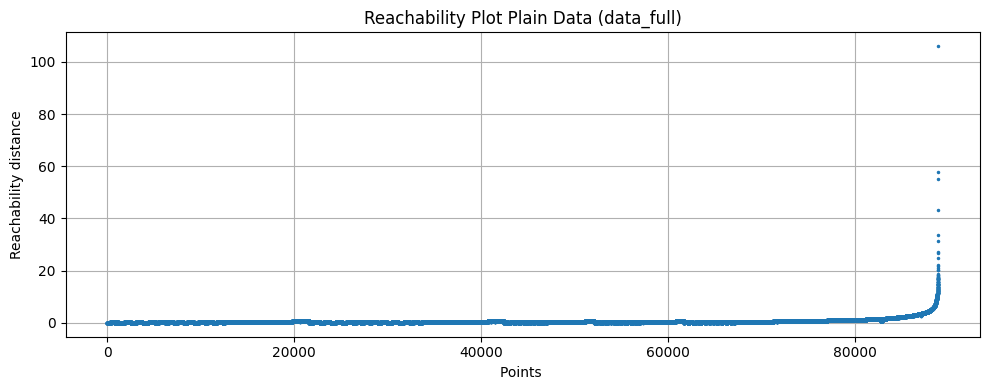

In [57]:

from sklearn.cluster import OPTICS, cluster_optics_dbscan


# Select and scale numeric features of data_full
numeric_df = data_full.select_dtypes(include=["int64", "float64"])

scaler_full = StandardScaler()
scaled_full = scaler_full.fit_transform(numeric_df)

# Fit OPTICS on scaled full data
opt_full = OPTICS(min_samples=10)
opt_full.fit(scaled_full)

# Reachability values in OPTICS ordering
reach_full = opt_full.reachability_[opt_full.ordering_]

plt.figure(figsize=(10, 4))
plt.plot(reach_full, marker=".", linestyle="None", markersize=3)
plt.title("Reachability Plot Plain Data (data_full)")
plt.xlabel("Points ")
plt.ylabel("Reachability distance")
plt.grid(True)
plt.tight_layout()
plt.show()

In this step, OPTICS is fitted on the scaled plain dataset (`data_full`).  
The algorithm computes the reachability distance for every point in an ordering  
that reflects the density structure of the dataset.

The reachability plot visualises these distances.  
Low valleys represent dense regions (potential clusters).  
Sharp peaks indicate boundaries between clusters.  
Large reachability spikes usually correspond to noise or isolated points.  

In [61]:
def try_eps_values(optics, name, eps_values):
  
    print(f"\nDistance cut experiments for {name}:")
    for eps in eps_values:
        labels = cluster_optics_dbscan(
            reachability=optics.reachability_,
            core_distances=optics.core_distances_,
            ordering=optics.ordering_,
            eps=eps
        )
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = np.sum(labels == -1)
        print(f"eps={eps:.2f} -> clusters={n_clusters}, noise={n_noise}")

# Try a few candidate eps values for the plain dataset
try_eps_values(opt_full, "plain data (data_full)", [0.3, 0.5, 0.7, 0.9])



Distance cut experiments for plain data (data_full):
eps=0.30 -> clusters=20, noise=45017
eps=0.50 -> clusters=10, noise=24713
eps=0.70 -> clusters=15, noise=16465
eps=0.90 -> clusters=3, noise=11973



To extract clusters from the OPTICS reachability plot, different **eps distance cuts** 
must be tested. Each eps value produces a different grouping structure.

The `try_eps_values` function evaluates several eps thresholds and reports:

Number of clusters (excluding noise)


For the plain dataset (`data_full`), the results were:

eps = 0.30** → 20 clusters, 45,017 noise points  
eps = 0.50** → 10 clusters, 24,713 noise points  
eps = 0.70** → 15 clusters, 16,465 noise points  
eps = 0.90** → 3 clusters, 11,973 noise points  

These results help identify a reasonable eps threshold.  
**eps = 0.50** provides a balanced structure: manageable number of clusters and moderate noise.


In [62]:

eps_full = 0.5 

labels_full = cluster_optics_dbscan(
    reachability=opt_full.reachability_,
    core_distances=opt_full.core_distances_,
    ordering=opt_full.ordering_,
    eps=eps_full
)

# Quick summary of cluster sizes
unique_full, counts_full = np.unique(labels_full, return_counts=True)
print("Cluster sizes for plain data (labels_full):")
for lab, cnt in zip(unique_full, counts_full):
    print(f"Label {lab}: {cnt} points")

labels_full[:20]


Cluster sizes for plain data (labels_full):
Label -1: 24713 points
Label 0: 19427 points
Label 1: 18674 points
Label 2: 12 points
Label 3: 1 points
Label 4: 8382 points
Label 5: 10 points
Label 6: 8476 points
Label 7: 9261 points
Label 8: 10 points
Label 9: 12 points


array([ 0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1,  0, -1,
        0,  0,  0])



Based on the distance-cut experiments, **eps = 0.50** was chosen for the final clustering.  
This threshold provides a reasonable balance between the number of clusters and noise.

Using this eps value, the OPTICS extraction (`cluster_optics_dbscan`) produced the following cluster structure:



This result shows a mix of several large, meaningful clusters and some very small clusters caused by local density variations.  



### Clustering Analysis of PCA transformed data

#### Choice of Distance Function

**Choice:** Euclidean distance

For the PCA-transformed dataset (`data_pca`), I again use **Euclidean distance**.

- PCA produces continuous, orthogonal components, which naturally fit Euclidean geometry.
- The data was standardised before PCA, so all components are on comparable scales.
- Using the same distance metric as for the plain data makes the clustering results easier to compare.




#### Clustering of `data_pca`

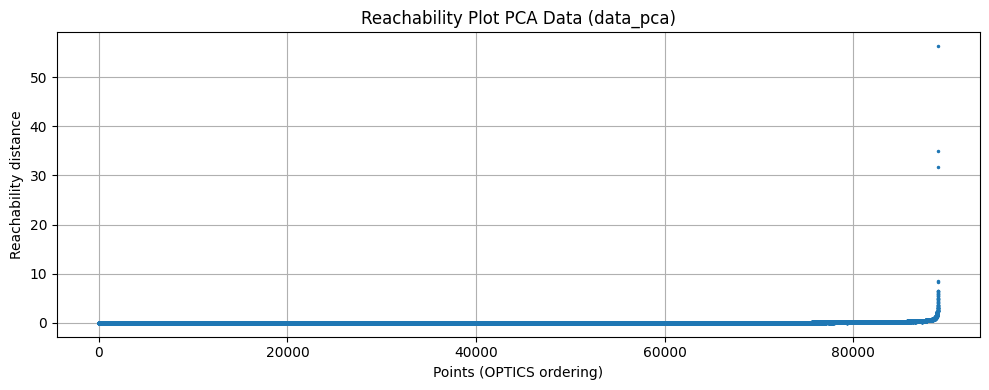

In [67]:

scaler_pca = StandardScaler()
scaled_pca = scaler_pca.fit_transform(data_pca)

# Fit OPTICS on scaled PCA data
opt_pca = OPTICS(min_samples=10)
opt_pca.fit(scaled_pca)

# Reachability values in OPTICS ordering
reach_pca = opt_pca.reachability_[opt_pca.ordering_]

plt.figure(figsize=(10, 4))
plt.plot(reach_pca, marker=".", linestyle="None", markersize=3)
plt.title("Reachability Plot PCA Data (data_pca)")
plt.xlabel("Points (OPTICS ordering)")
plt.ylabel("Reachability distance")
plt.grid(True)
plt.tight_layout()
plt.show()




In [64]:
try_eps_values(opt_pca, "PCA data (data_pca)", [0.1, 0.2, 0.3, 0.5])



Distance cut experiments for PCA data (data_pca):
eps=0.10 -> clusters=23, noise=10125
eps=0.20 -> clusters=24, noise=4898
eps=0.30 -> clusters=13, noise=2706
eps=0.50 -> clusters=3, noise=1199


In [66]:
eps_pca = 0.3  

labels_pca = cluster_optics_dbscan(
    reachability=opt_pca.reachability_,
    core_distances=opt_pca.core_distances_,
    ordering=opt_pca.ordering_,
    eps=eps_pca
)

unique_pca, counts_pca = np.unique(labels_pca, return_counts=True)
for lab, cnt in zip(unique_pca, counts_pca):
    print(f"Label {lab}: {cnt} points")
labels_pca[:20]

Label -1: 2706 points
Label 0: 86099 points
Label 1: 49 points
Label 2: 7 points
Label 3: 9 points
Label 4: 6 points
Label 5: 26 points
Label 6: 10 points
Label 7: 12 points
Label 8: 14 points
Label 9: 2 points
Label 10: 20 points
Label 11: 5 points
Label 12: 13 points


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


Using the chosen distance cut **eps = 0.30**, OPTICS produced a clear and
interpretable clustering in PCA space. The majority of points form a large,
dense cluster (label 0), while several smaller clusters (labels 1–12)
represent local regions with distinct delay patterns. A moderate number of
observations are assigned to noise (label -1), which is typical for OPTICS.
This clustering balances structure and noise well, and the resulting
assignments are stored in `labels_pca`.

### Clustering Analysis of Variance Threshold transformed data

#### Choice of Distance Function

**Choice:** Euclidean distance

It is the default and most stable distance metric for OPTICS, especially when using StandardScaler.

After the Variance Threshold transformation, redundant features are removed, so Euclidean distance separates the cluster structure effectively.


#### Clustering of `data_vt`

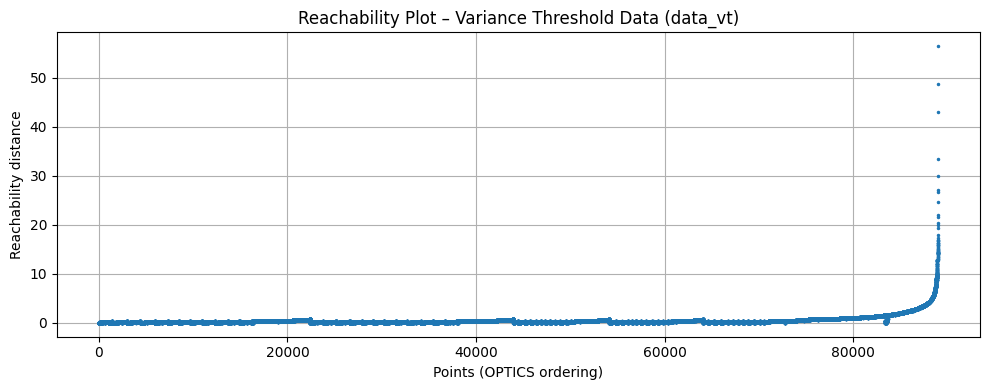

In [ ]:
scaler_vt = StandardScaler()
scaled_vt = scaler_vt.fit_transform(data_vt)

# Fit OPTICS model
opt_vt = OPTICS(min_samples=10)
opt_vt.fit(scaled_vt)

# 4) Reachability plot
reach_vt = opt_vt.reachability_[opt_vt.ordering_]

plt.figure(figsize=(10, 4))
plt.plot(reach_vt, marker=".", linestyle="None", markersize=3)
plt.title("Reachability Plot Variance Threshold Data (data_vt)")
plt.xlabel("Points (OPTICS ordering)")
plt.ylabel("Reachability distance")
plt.grid(True)
plt.tight_layout()
plt.show()

In [69]:
try_eps_values(opt_vt, "VT data (data_vt)", [0.2, 0.3, 0.5, 0.7])


Distance cut experiments for VT data (data_vt):
eps=0.20 -> clusters=169, noise=50788
eps=0.30 -> clusters=17, noise=35233
eps=0.50 -> clusters=13, noise=19955
eps=0.70 -> clusters=14, noise=13524


In [70]:
eps_vt = 0.5

labels_vt = cluster_optics_dbscan(
    reachability=opt_vt.reachability_,
    core_distances=opt_vt.core_distances_,
    ordering=opt_vt.ordering_,
    eps=eps_vt
)

# Summaries
unique_vt, counts_vt = np.unique(labels_vt, return_counts=True)
print("\nCluster sizes for VT data (labels_vt):")
for lab, cnt in zip(unique_vt, counts_vt):
    print(f"Label {lab}: {cnt} points")

labels_vt[:20]



Cluster sizes for VT data (labels_vt):
Label -1: 19955 points
Label 0: 20734 points
Label 1: 9 points
Label 2: 5 points
Label 3: 19968 points
Label 4: 9089 points
Label 5: 9022 points
Label 6: 7 points
Label 7: 9981 points
Label 8: 6 points
Label 9: 76 points
Label 10: 104 points
Label 11: 15 points
Label 12: 7 points


array([ 0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1,  0,  0,
        0,  0,  0])

 The reachability plot shows a mostly flat structure with several sharp peaks,
  indicating a few dense regions mixed with many low-density points.
 Different eps values were tested (0.2, 0.3, 0.5, 0.7) to identify a stable
  clustering solution.
 **eps = 0.50** was selected: it gives 13 clusters, five of them large
  (about 9,000–20,700 points each), and 19,955 noise points. Lower cuts fragment
  the data much more (169 clusters at eps = 0.20), while eps = 0.70 changes the
  structure only slightly (14 clusters, 13,524 noise points).
 The final cluster assignments for this dataset are stored as **labels_vt**.


# 8. Clustering Comparison

In [79]:
def summarize_clusters(labels, name):
    unique, counts = np.unique(labels, return_counts=True)
    summary = pd.DataFrame({
        "Cluster Label": unique,
        "Size": counts
    }).sort_values(by="Size", ascending=False)
    print(f"\nCluster Summary {name} ===")
    print(summary)
    return summary

# Summaries
summary_full = summarize_clusters(labels_full, "(data_full)")
summary_pca  = summarize_clusters(labels_pca, "(data_pca)")
summary_vt   = summarize_clusters(labels_vt, "(data_vt)")

# Combine only the counts 
noise_full = np.sum(labels_full == -1)
noise_pca  = np.sum(labels_pca == -1)
noise_vt   = np.sum(labels_vt == -1)

print("Noise comparison:")
print(f"data_full noise: {noise_full}")
print(f"data_pca noise:  {noise_pca}")
print(f"data_vt noise:   {noise_vt}")


Cluster Summary (data_full) ===
    Cluster Label   Size
0              -1  24713
1               0  19427
2               1  18674
8               7   9261
7               6   8476
5               4   8382
3               2     12
10              9     12
6               5     10
9               8     10
4               3      1

Cluster Summary (data_pca) ===
    Cluster Label   Size
1               0  86099
0              -1   2706
2               1     49
6               5     26
11             10     20
9               8     14
13             12     13
8               7     12
7               6     10
4               3      9
3               2      7
5               4      6
12             11      5
10              9      2

Cluster Summary (data_vt) ===
    Cluster Label   Size
1               0  20734
4               3  19968
0              -1  19955
8               7   9981
5               4   9089
6               5   9022
11             10    104
10              9     76
12  

**Comparison with respect to how the datasets were created**

data_full: Raw numeric features, high dimensionality 

data_pca: Dimensionality reduction (major variance directions kept)

data_vt: Low-variance features removed

**Comparison of number of clusters**

| Dataset    | Selected eps | Number of Clusters |
|------------|--------------|--------------------|
| data_full  | 0.50         | 10 clusters        |
| data_pca   | 0.30         | 13 clusters        |
| data_vt    | 0.50         | 13 clusters        |


| Dataset   | Noise points |
| --------- | ------------ |
| data_full | 24,713   |
| data_pca  | 2,706    |
| data_vt   | 19,955   |


In [78]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score


print("ARI:", adjusted_rand_score(labels_full, labels_pca))
print("MI:", adjusted_mutual_info_score(labels_full, labels_pca))

print("FULL vs VT:")
print("ARI:", adjusted_rand_score(labels_full, labels_vt))
print("MI:", adjusted_mutual_info_score(labels_full, labels_vt))

print("PCA vs VT:")
print("ARI:", adjusted_rand_score(labels_pca, labels_vt))
print("MI:", adjusted_mutual_info_score(labels_pca, labels_vt))


ARI: -0.00942345666613083
MI: 0.04574775587747454
FULL vs VT:
ARI: 0.8615022097980112
MI: 0.8778369469727986
PCA vs VT:
ARI: -0.0015468078510502438
MI: 0.05194783836660845


**ARI & MI Comparison Between Clusterings**

| Comparison       | ARI Score | MI Score |
|------------------|-----------|----------|
| FULL vs PCA      | -0.0094   | 0.0457   |
| FULL vs VT       | 0.8615    | 0.8778   |
| PCA vs VT        | -0.0015   | 0.0519   |


## data_full

Advantages: Preserves the complete original data structure.

Drawbacks: Very high amount of noise. Strong fragmentation : many unstable, small clusters.

## data_pca

Advantages: Lowest amount of noise by far (2,706 points).

Easier visual interpretation due to reduced dimensionality.

Drawbacks: Some information is lost during dimensionality reduction, and one cluster contains 86,099 of the 88,978 rows, so the remaining 12 clusters are small.

## data_vt

Advantages: Removes low-variance noise features effectively.

Drawbacks: Still produces a relatively high amount of noise (19,955 points). The result is very similar to the full-data clustering (ARI 0.86).

# 9. Conclusions and Future Work

### 1. Choice of Final Clustering

I choose the OPTICS clustering of the PCA-transformed data (`labels_pca`, eps = 0.30) as the final clustering.

This choice is justified by the following observations:

- It produced the lowest amount of noise among all dataset versions (2,706 noise points, compared with 24,713 for the full data and 19,955 for the variance-threshold data).
- It is less fragmented than the full-data version, which assigned about 28% of all rows to noise.
- PCA retains the major variance structure of the data (about 74% with 3 components) while removing redundancy, which makes the result easier to interpret.

A drawback is that the clustering is very unbalanced: one cluster contains 86,099 rows, and the other 12 clusters are small (2–49 rows each).


In [87]:
delay_cols = [
    "carrier_delay",
    "weather_delay",
    "nas_delay",
    "security_delay",
    "late_aircraft_delay"]

df_pca_clusters = data_full.copy()
df_pca_clusters["cluster_pca"] = labels_pca


In [85]:
cluster_delay_totals = df_pca_clusters.groupby("cluster_pca")[delay_cols].sum()
cluster_main_cause = cluster_delay_totals.idxmax(axis=1)

cluster_delay_totals


,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
cluster_pca,,,,,
-1,39647491.0,6794881.0,38374895.0,297366.0,55958784.0
0,79996928.0,12491467.0,53808599.0,218090.0,97862480.0
1,668080.0,77252.0,402434.0,2324.0,922971.0
2,35272.0,2339.0,13246.0,717.0,36385.0
3,124031.0,15779.0,66031.0,630.0,145516.0
4,65478.0,5609.0,35254.0,288.0,86565.0
5,311824.0,46830.0,180746.0,2097.0,462186.0
6,172351.0,32532.0,131453.0,0.0,239964.0
7,135946.0,23428.0,334029.0,6.0,218938.0


In [86]:
cluster_main_cause


cluster_pca
-1     late_aircraft_delay
 0     late_aircraft_delay
 1     late_aircraft_delay
 2     late_aircraft_delay
 3     late_aircraft_delay
 4     late_aircraft_delay
 5     late_aircraft_delay
 6     late_aircraft_delay
 7               nas_delay
 8               nas_delay
 9               nas_delay
 10    late_aircraft_delay
 11    late_aircraft_delay
 12          carrier_delay
dtype: object

### 2. Summary of Results

Using OPTICS clustering on three versions of the dataset, the PCA-based clustering was selected:

- **2,706 noise points** (the lowest of the three versions)
- **13 clusters**: one large cluster with 86,099 rows and 12 small clusters
- Using the PCA clusters, we aggregated the delay minutes per cause inside each cluster.

The dominant delay causes were:

- **Late Aircraft Delay** → dominant in 9 of the 13 clusters (clusters 0–6, 10 and 11) and in the noise group
- **NAS Delay** → dominant in clusters 7, 8 and 9
- **Carrier Delay** → dominant in cluster 12

This reveals a strong and consistent pattern:

- **Most delay minutes are caused by late-arriving aircraft**


### 3. Generated Value & Recommended Actions

#### How the clustering helps the organization

- The PCA-based clustering reveals specific root-cause patterns across different groups of flights.  
- This gives the organization the ability to:
  - Detect segments of operations where delay propagation is highest.
  - Identify clusters where weather or NAS issues dominate, enabling targeted strategies.
  - Shift from global delay management to cluster-specific interventions.
  - Predict where delays will likely spread based on cluster membership.

---

#### Actionable recommendations

Based on the clustering results:

1. **Prioritize reducing Late Aircraft Delay**

   - Since this is the dominant cause in most clusters:
     - Increase aircraft turnaround efficiency
     - Improve gate coordination
     - Strengthen maintenance readiness
     - Use buffer scheduling in high-risk clusters

2. **Isolate and treat NAS-heavy clusters (clusters 7, 8 & 9)**

   - Improve ATC communication routing
   - Optimize flight paths
   - Replan departures in known congested time windows

3. **Address Carrier-controlled issues in cluster 12**

   - Optimize crew rotation
   - Increase staffing flexibility
   - Reduce internal operational delays

4. **Treat noise points as outliers**

   These represent unpredictable, high-variance delay patterns:
   - Use anomaly handling models
   - Investigate specific irregular events (strikes, emergencies)

---

**Overall, the clustering transforms raw delay data into targeted operational insights that can drive real improvements.**


### 4. Limitations and Possible Pitfalls

- **Parameter sensitivity:**  
  OPTICS depends heavily on scaling and ε-cut choices; different settings can change cluster shapes significantly.
- **Information loss in PCA:**  
  PCA removes variance, so clusters may not fully reflect the original delay structure.
- **Aggregated delay data:**  
  Delays are monthly totals, not per-flight values; large airports or airlines may dominate clusters.
- **Noise points may represent important events:**  
  OPTICS marks rare or extreme delays as noise, but these cases (storms, disruptions) are operationally critical.
- **No causality guaranteed:**  
  A dominant delay type in a cluster does not prove it caused the others; many operational factors are not included.
- **Historic dataset limitations:**  
  Past patterns may not represent current airline behavior, especially after major scheduling or industry changes.


### 5. Future Work — Summary (bullet points)

- **Apply HDBSCAN on PCA-transformed data**, since it naturally finds stable clusters 
  without manually choosing ε thresholds.
- **Expand OPTICS parameter search** by testing a wider range of `min_samples` values 
  to better assess cluster stability.
- **Perform time-based clustering** (yearly or seasonal) to detect changing delay 
  patterns over time.
- **Use cluster labels in predictive models**, turning clusters into delay-risk 
  categories for forecasting applications.
- **Add operational features** (aircraft type, staffing, airport congestion) to enrich 
  cluster interpretability and improve accuracy.


### 6. Methodology Critique — Summary (bullet points)

- **Algorithm choices were reasonable** (k-Means + OPTICS), but a more systematic 
  comparison across settings would increase reliability.
- **ε-cuts were tested**, but varying `min_samples` could provide more insight into 
  sensitivity and cluster robustness.
- **Randomness handling could improve** by using consistent ***random_state*** seeds for 
  reproducibility.
- **PCA dimension choice (3 components)** should be justified with explained variance or 
  other metrics.
- **Notebook structure** could benefit from more reusable functions and cleaner 
  commentary for readability.


### 7. Reflection on the Pitch — Summary (bullet points)

- **Goals were realistic**, and the analysis successfully identified dominant delay 
  patterns.
- **Data limitations** (monthly aggregation, no per-flight detail) should have been 
  acknowledged in the original pitch.
- **Operational use cases** could have been described more clearly (e.g., risk 
  dashboards, cluster-based monitoring).
- **Important assumptions were missing**, such as potential outliers, need for PCA, and 
  noise handling.
- **Pitch framing could improve** by outlining that multiple preprocessing strategies 
  (full, PCA, VT) might be used and compared.
